# Notebook 04: Statistical Trend Evaluation & Multivariate Pattern Recognition
**Project:** `Fabric_FYP` — Quantitative Color and Texture Analysis of Degraded Cotton and Polyester Fabrics

This final analytical notebook fulfills **Specific Objectives 2 and 3** across the **30-day exposure timeline** (`Days 0, 2, 4, ..., 30`, collected at 2-day intervals across Sessions `D0–D15`) using the extracted colorimetric and micro-textural dataset (`master_features.csv`):
1. **Objective 2 — Statistical & Temporal Degradation Modeling:**
   * **Two-Way ANOVA & Tukey's HSD ($\alpha = 0.05$):** Evaluates statistically significant differences across **Fabric Type** (`Cotton` vs. `Polyester`), **Exposure Environment** (`Control`, `Indoor`, `Outdoor`), and their interaction.
   * **Non-Linear Regression Curve Fitting:** Models temporal degradation trajectories from `Day 0` to `Day 30` for $\Delta E_{76}$, $\Delta b^*$, **GLCM Contrast**, and **Canny Edge Density**.
   * **Micro-Climate Correlation:** Links color and texture shifts against recorded Temperature ($^\circ\text{C}$) and Relative Humidity ($\%$) logs (`data/metadata/environmental_logs.xlsx`, when supplied).
2. **Objective 3 — Multivariate Pattern Recognition & Clustering:**
   * **Principal Component Analysis (PCA):** Identifies which color and texture metrics drive primary variance across degraded fabrics.
   * **Linear Discriminant Analysis (LDA):** Tests supervised separability across 30-day exposure stages (`Control Day 0`, `Early Days 2–10`, `Mid Days 12–20`, `Late Days 22–30`).
   * **Hierarchical Cluster Analysis (HCA):** Generates a Ward-linkage dendrogram revealing natural sample groupings based solely on combined color and texture signatures.

In [1]:
import sys
import importlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.preprocessing import StandardScaler

# Resolve Fabric_FYP project root dynamically
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
assert PROJECT_ROOT.name == "Fabric_FYP", f"Expected project root 'Fabric_FYP', got '{PROJECT_ROOT.name}'"

if str(PROJECT_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "src"))

import fabric_taphonomy.analysis as an
importlib.reload(an)  # Always load latest saved version of analysis.py
from fabric_taphonomy.analysis import (
    CORE_FEATURES,
    run_two_way_anova_suite,
    fit_temporal_curves,
    load_and_aggregate_logger_data,
    correlate_environmental_logs,
    run_pca_and_lda,
)

# Define directories
TABLES_DIR = PROJECT_ROOT / "outputs" / "tables"
FIGURES_DIR = PROJECT_ROOT / "outputs" / "figures"
METADATA_DIR = PROJECT_ROOT / "data" / "metadata"

master_df = pd.read_csv(TABLES_DIR / "master_features.csv")
assert master_df["day"].max() == 30, f"Expected max exposure day 30, got {master_df['day'].max()}. Re-run Notebook 03 first!"

plt.rcParams.update({"figure.dpi": 150, "savefig.dpi": 300})
print(f"Loaded master feature table: {len(master_df)} eligible specimens across {master_df['group_code'].nunique()} groups.")
print(f"Exposure timeline verified : Days {sorted(master_df['day'].unique())}")

Loaded master feature table: 130 eligible specimens across 10 groups.
Exposure timeline verified : Days [np.int64(0), np.int64(2), np.int64(4), np.int64(6), np.int64(8), np.int64(10), np.int64(12), np.int64(14), np.int64(16), np.int64(18), np.int64(20), np.int64(22), np.int64(24), np.int64(26), np.int64(28), np.int64(30)]


## 1. Two-Way ANOVA & Post-Hoc Tukey's HSD ($\alpha = 0.05$)
To determine which quantitative metrics reliably distinguish **Cotton vs. Polyester** and **Indoor vs. Outdoor** weathering, a Type-II Two-Way Analysis of Variance (`Fabric × Setting`) is performed across key colorimetric and textural features, accompanied by partial eta-squared ($\eta^2$) effect sizes and pairwise **Tukey's HSD** comparisons.

In [2]:
key_metrics = [
    "delta_E", "delta_L", "delta_b", "hsv_S_pct",
    "glcm_contrast", "glcm_homogeneity", "glcm_energy",
    "lbp_entropy", "canny_edge_pct"
]

anova_df, tukey_df = run_two_way_anova_suite(master_df, metrics=key_metrics)

anova_df.to_csv(TABLES_DIR / "two_way_anova_results.csv", index=False)
tukey_df.to_csv(TABLES_DIR / "tukey_hsd_posthoc.csv", index=False)

print("Two-Way ANOVA Results (Fabric x Setting):")
display(anova_df)

print("\nSignificant Pairwise Group Differences (Tukey's HSD, reject = True):")
display(tukey_df[tukey_df["reject"] == True].head(24))

Two-Way ANOVA Results (Fabric x Setting):


,feature,factor,F_stat,p_value,eta_squared,significant_005
0,delta_E,fabric,0.3732,0.542357,0.0020,False
1,delta_E,setting,29.8468,0.000000,0.3240,True
2,delta_E,fabric:setting,0.0921,0.912115,0.0010,False
3,delta_L,fabric,0.2154,0.643411,0.0017,False
4,delta_L,setting,2.8725,0.060329,0.0442,False
5,delta_L,fabric:setting,0.0610,0.940856,0.0009,False
6,delta_b,fabric,0.3488,0.555858,0.0018,False
7,delta_b,setting,33.3123,0.000000,0.3485,True
8,delta_b,fabric:setting,0.1060,0.899515,0.0011,False
9,hsv_S_pct,fabric,45.9039,0.000000,0.1751,True



Significant Pairwise Group Differences (Tukey's HSD, reject = True):


,feature,group1,group2,meandiff,p-adj,lower,upper,reject
1,delta_E,Cotton_Control,Cotton_Outdoor,11.0971,0.0122,1.5935,20.6007,True
4,delta_E,Cotton_Control,Polyester_Outdoor,10.0028,0.0329,0.4992,19.5064,True
5,delta_E,Cotton_Indoor,Cotton_Outdoor,10.6865,0.0000,4.6759,16.6971,True
8,delta_E,Cotton_Indoor,Polyester_Outdoor,9.5922,0.0001,3.5816,15.6028,True
9,delta_E,Cotton_Outdoor,Polyester_Control,-10.9102,0.0145,-20.4137,-1.4066,True
10,delta_E,Cotton_Outdoor,Polyester_Indoor,-10.7000,0.0000,-16.7106,-4.6894,True
13,delta_E,Polyester_Control,Polyester_Outdoor,9.8158,0.0386,0.3123,19.3194,True
14,delta_E,Polyester_Indoor,Polyester_Outdoor,9.6057,0.0001,3.5951,15.6163,True
31,delta_b,Cotton_Control,Cotton_Outdoor,11.5582,0.0097,1.8686,21.2477,True
34,delta_b,Cotton_Control,Polyester_Outdoor,10.4412,0.0268,0.7516,20.1307,True


## 2. Non-Linear Temporal Degradation Curve Fitting (Days 0–30)
To evaluate how color shift ($\Delta E_{76}$), yellowing ($\Delta b^*$), surface roughness (**GLCM Contrast**), and thread fraying (**Canny Edge Density**) evolve across the **30-day exposure period**, exponential saturation curves:
$$y(t) = a\left(1 - e^{-kt}\right) + c$$
are fitted from `Day 0` through `Day 30` comparing **Cotton** and **Polyester** under **Indoor** and **Outdoor** conditions.

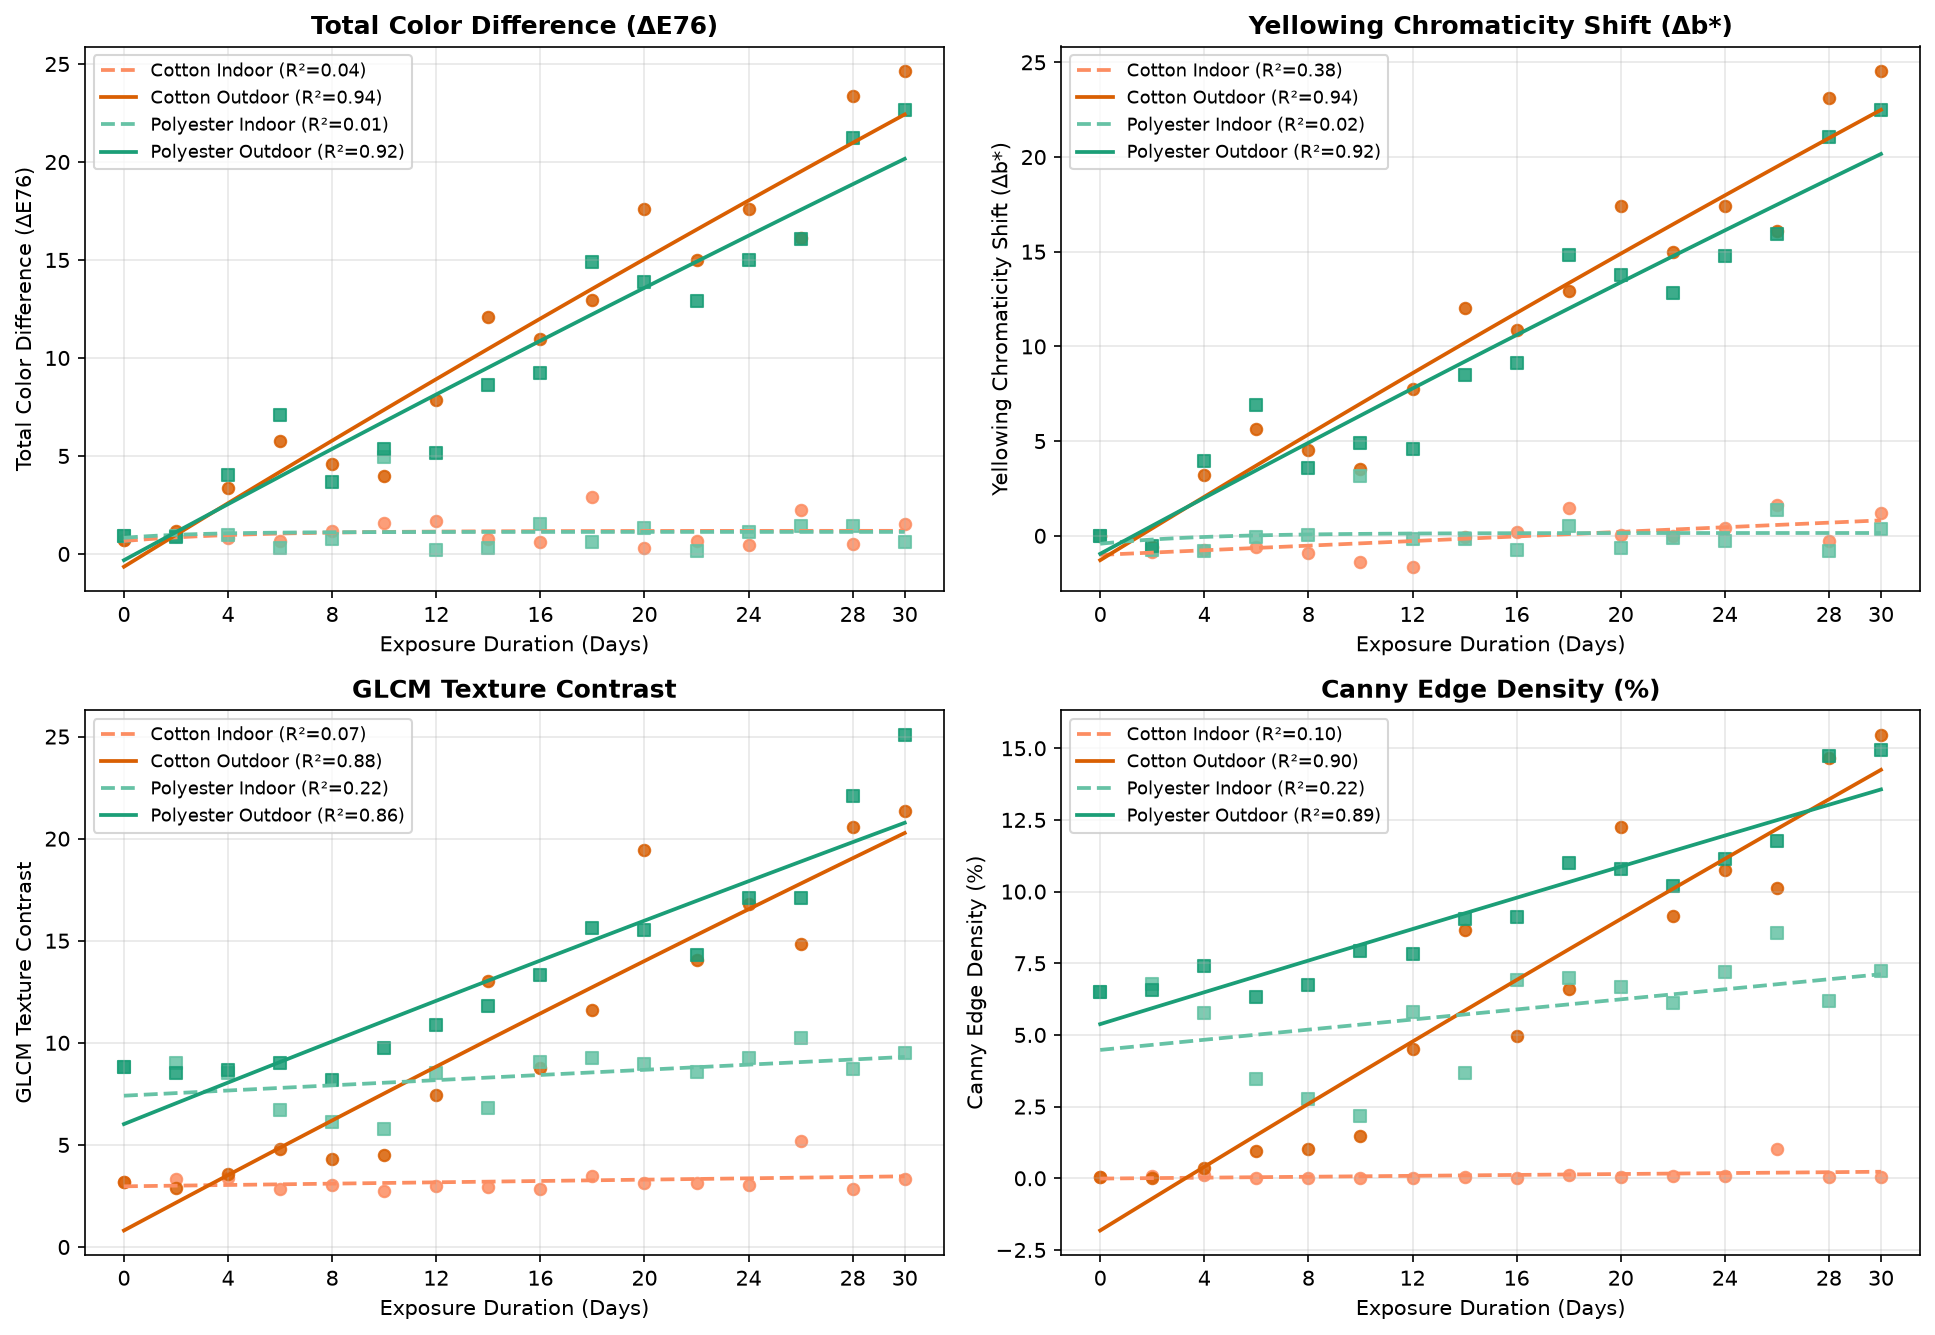

,metric,fabric,setting,amplitude_a,rate_k_per_day,baseline_c,R_squared
0,delta_E,Cotton,Indoor,0.5209,0.2199,0.6597,0.0421
1,delta_E,Cotton,Outdoor,200.0000,0.0041,-0.6509,0.9375
2,delta_E,Polyester,Indoor,0.3017,0.3520,0.8239,0.0052
3,delta_E,Polyester,Outdoor,200.0000,0.0036,-0.3186,0.9170
4,delta_b,Cotton,Indoor,200.0000,0.0003,-1.0069,0.3786
5,delta_b,Cotton,Outdoor,200.0000,0.0042,-1.2853,0.9404
6,delta_b,Polyester,Indoor,0.5680,0.2487,-0.4184,0.0249
7,delta_b,Polyester,Outdoor,200.0000,0.0037,-0.9494,0.9175
8,glcm_contrast,Cotton,Indoor,163.5525,0.0001,2.9724,0.0742
9,glcm_contrast,Cotton,Outdoor,200.0000,0.0034,0.8099,0.8766


Saved temporal regression figure to: /Users/anna/PycharmProjects/Fabric_FYP/outputs/figures/temporal_degradation_curves.png


In [3]:
curve_metrics = [
    ("delta_E", "Total Color Difference (ΔE76)"),
    ("delta_b", "Yellowing Chromaticity Shift (Δb*)"),
    ("glcm_contrast", "GLCM Texture Contrast"),
    ("canny_edge_pct", "Canny Edge Density (%)"),
]

all_fit_tables = []
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
axes = axes.ravel()

palette = {
    ("Cotton", "Outdoor"): ("#d95f02", "o", "-"),
    ("Cotton", "Indoor"): ("#fc8d62", "o", "--"),
    ("Polyester", "Outdoor"): ("#1b9e77", "s", "-"),
    ("Polyester", "Indoor"): ("#66c2a5", "s", "--"),
}

day_ticks = [0, 4, 8, 12, 16, 20, 24, 28, 30]

for idx, (metric, ylabel) in enumerate(curve_metrics):
    fit_df, curves = fit_temporal_curves(master_df, metric=metric)
    all_fit_tables.append(fit_df)
    ax = axes[idx]

    for (fab, setting), (t_data, y_data, t_smooth, y_smooth, r_sq) in curves.items():
        color, marker, linestyle = palette[(fab, setting)]
        ax.scatter(t_data, y_data, color=color, marker=marker, s=30, alpha=0.85)
        ax.plot(
            t_smooth, y_smooth, color=color, linestyle=linestyle, linewidth=1.8,
            label=f"{fab} {setting} (R²={r_sq:.2f})"
        )

    ax.set_title(ylabel, fontweight="bold")
    ax.set_xlabel("Exposure Duration (Days)")
    ax.set_ylabel(ylabel)
    ax.set_xticks(day_ticks)
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8.5, frameon=True)

curve_fits_df = pd.concat(all_fit_tables, ignore_index=True)
curve_fits_df.to_csv(TABLES_DIR / "temporal_curve_fits.csv", index=False)

plt.tight_layout()
curve_fig_path = FIGURES_DIR / "temporal_degradation_curves.png"
plt.savefig(curve_fig_path, dpi=300)
plt.show()

display(curve_fits_df)
print("Saved temporal regression figure to:", curve_fig_path)

## 3. Environmental Micro-Climate Correlation (`INDOOR_DATA_LOGGER.xlsx` & `OUTDOOR__DATA_LOGGER.xlsx`)
Hourly Temperature ($^\circ\text{C}$), Relative Humidity ($\%$), and Dew Point ($^\circ\text{C}$) logs from `data/metadata/` are cleaned (stripping header summary rows) and aggregated into 2-day exposure intervals (`Days 2, 4, ..., 30`) to tally directly with `master_features.csv`. Both **2-day interval** and **cumulative exposure** micro-climate metrics are correlated against fabric color and texture shifts using Pearson ($r$) and Spearman ($\rho$) coefficients.

Aligned 30-Day Micro-Climate Logger Summary (Indoor vs. Outdoor):


,setting,day,n_logger_readings,interval_temp_mean,interval_temp_max,interval_rh_mean,interval_rh_max,interval_dew_mean,cum_temp_mean,cum_rh_mean,cum_dew_mean
0,Indoor,2,48,30.079,38.0,82.677,94.8,26.319,30.079,82.677,26.319
1,Indoor,4,48,28.954,37.2,87.242,96.5,26.248,29.517,84.959,26.283
2,Indoor,6,48,29.204,37.5,87.523,97.2,26.552,29.412,85.814,26.373
3,Indoor,8,48,28.948,35.9,87.156,94.8,26.275,29.296,86.149,26.348
4,Indoor,10,48,29.679,36.8,84.246,94.3,26.348,29.373,85.769,26.348
5,Indoor,12,48,29.219,37.2,84.248,92.7,25.877,29.347,85.515,26.270
6,Indoor,14,48,28.388,36.4,91.377,98.9,26.598,29.210,86.353,26.317
7,Indoor,16,48,28.313,36.8,92.000,99.1,26.625,29.098,87.059,26.355
8,Indoor,18,48,29.323,35.4,89.727,97.9,27.194,29.123,87.355,26.448
9,Indoor,20,48,28.560,36.7,92.440,99.5,26.979,29.067,87.864,26.501



Top Significant Micro-Climate vs. Fabric Degradation Correlations:


,env_variable,fabric_feature,pearson_r,pearson_p,spearman_rho,spearman_p,significant_005
0,interval_temp_mean,delta_E,-0.5601,0.0,-0.6213,0.000000,True
43,interval_dew_mean,lbp_entropy,0.6305,0.0,0.4486,0.000000,True
45,cum_temp_mean,delta_E,-0.6634,0.0,-0.8307,0.000000,True
47,cum_temp_mean,delta_b,-0.6935,0.0,-0.8484,0.000000,True
48,cum_temp_mean,hsv_S_pct,0.6815,0.0,0.7205,0.000000,True
49,cum_temp_mean,glcm_contrast,-0.5343,0.0,-0.6721,0.000000,True
51,cum_temp_mean,glcm_energy,0.5601,0.0,0.6561,0.000000,True
52,cum_temp_mean,lbp_entropy,0.8366,0.0,0.7704,0.000000,True
53,cum_temp_mean,canny_edge_pct,-0.5362,0.0,-0.6752,0.000000,True
16,interval_temp_max,lbp_entropy,0.4448,0.0,0.3697,0.000032,True


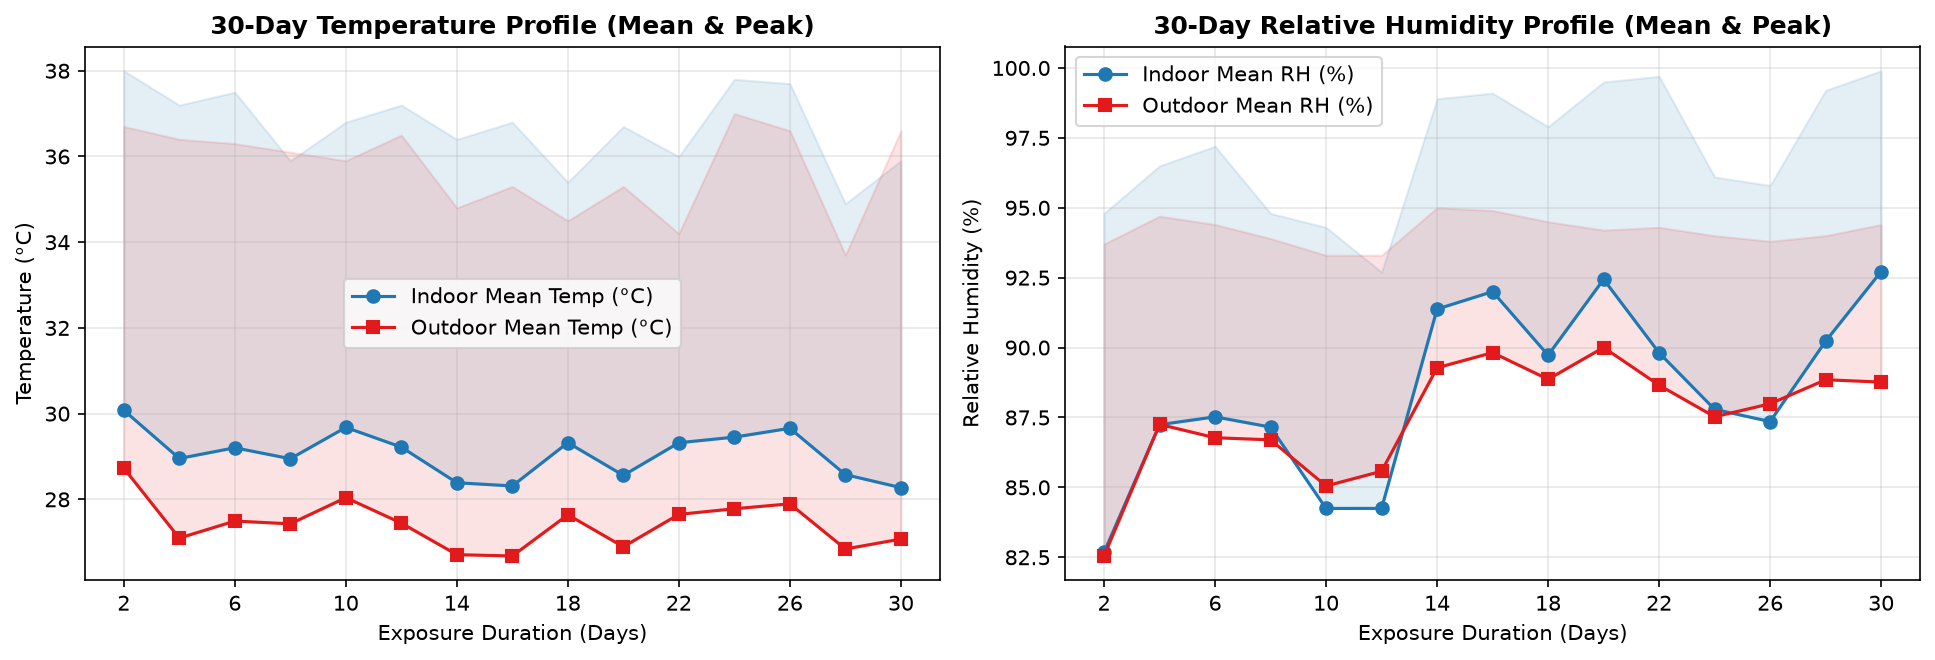

Saved micro-climate profile figure to: /Users/anna/PycharmProjects/Fabric_FYP/outputs/figures/environmental_logger_profiles.png


In [4]:
# Load and align INDOOR_DATA_LOGGER.xlsx and OUTDOOR__DATA_LOGGER.xlsx to Days 2..30
logger_summary_df = load_and_aggregate_logger_data(METADATA_DIR)
logger_summary_df.to_csv(TABLES_DIR / "processed_logger_summary.csv", index=False)

env_corr_df, merged_env_df = correlate_environmental_logs(
    master_df=master_df,
    logger_summary_df=logger_summary_df,
    fabric_metrics=key_metrics,
)
env_corr_df.to_csv(TABLES_DIR / "environmental_correlations.csv", index=False)

print("Aligned 30-Day Micro-Climate Logger Summary (Indoor vs. Outdoor):")
display(logger_summary_df.head(10))

print("\nTop Significant Micro-Climate vs. Fabric Degradation Correlations:")
display(env_corr_df.sort_values("pearson_p").head(16))

# Plot 2-panel Micro-Climate Overview (Temperature & RH across Days 2..30)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
day_ticks = [2, 6, 10, 14, 18, 22, 26, 30]

for setting, color, marker in [("Indoor", "#1f78b4", "o"), ("Outdoor", "#e31a1c", "s")]:
    sub = logger_summary_df[logger_summary_df["setting"] == setting]
    axes[0].plot(sub["day"], sub["interval_temp_mean"], color=color, marker=marker, label=f"{setting} Mean Temp (°C)")
    axes[0].fill_between(sub["day"], sub["interval_temp_mean"], sub["interval_temp_max"], color=color, alpha=0.12)

    axes[1].plot(sub["day"], sub["interval_rh_mean"], color=color, marker=marker, label=f"{setting} Mean RH (%)")
    axes[1].fill_between(sub["day"], sub["interval_rh_mean"], sub["interval_rh_max"], color=color, alpha=0.12)

axes[0].set_title("30-Day Temperature Profile (Mean & Peak)", fontweight="bold")
axes[0].set_xlabel("Exposure Duration (Days)")
axes[0].set_ylabel("Temperature (°C)")
axes[0].set_xticks(day_ticks)
axes[0].grid(True, alpha=0.3)
axes[0].legend()

axes[1].set_title("30-Day Relative Humidity Profile (Mean & Peak)", fontweight="bold")
axes[1].set_xlabel("Exposure Duration (Days)")
axes[1].set_ylabel("Relative Humidity (%)")
axes[1].set_xticks(day_ticks)
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.tight_layout()
env_fig_path = FIGURES_DIR / "environmental_logger_profiles.png"
plt.savefig(env_fig_path, dpi=300)
plt.show()
print("Saved micro-climate profile figure to:", env_fig_path)

## 4. Multivariate Pattern Recognition: PCA Biplot & Linear Discriminant Analysis (LDA)
To fulfill **Specific Objective 3**, all 13 standardized color and texture features are analyzed simultaneously:
* **Principal Component Analysis (PCA):** Projects samples onto orthogonal axes (`PC1` and `PC2`) capturing maximum dataset variance. Feature loading vectors (arrows) reveal which color and texture parameters drive separation between **Cotton vs. Polyester** and **Indoor vs. Outdoor** weathering.
* **Linear Discriminant Analysis (LDA):** Evaluates supervised separation across 30-day exposure stages (`Control Day 0`, `Early Days 2–10`, `Mid Days 12–20`, and `Late Days 22–30`).

PCA Explained Variance -> PC1: 68.58% | PC2: 17.62% (Cumulative: 86.20%)
LDA 30-Day Stage Separation Accuracy: 56.15%


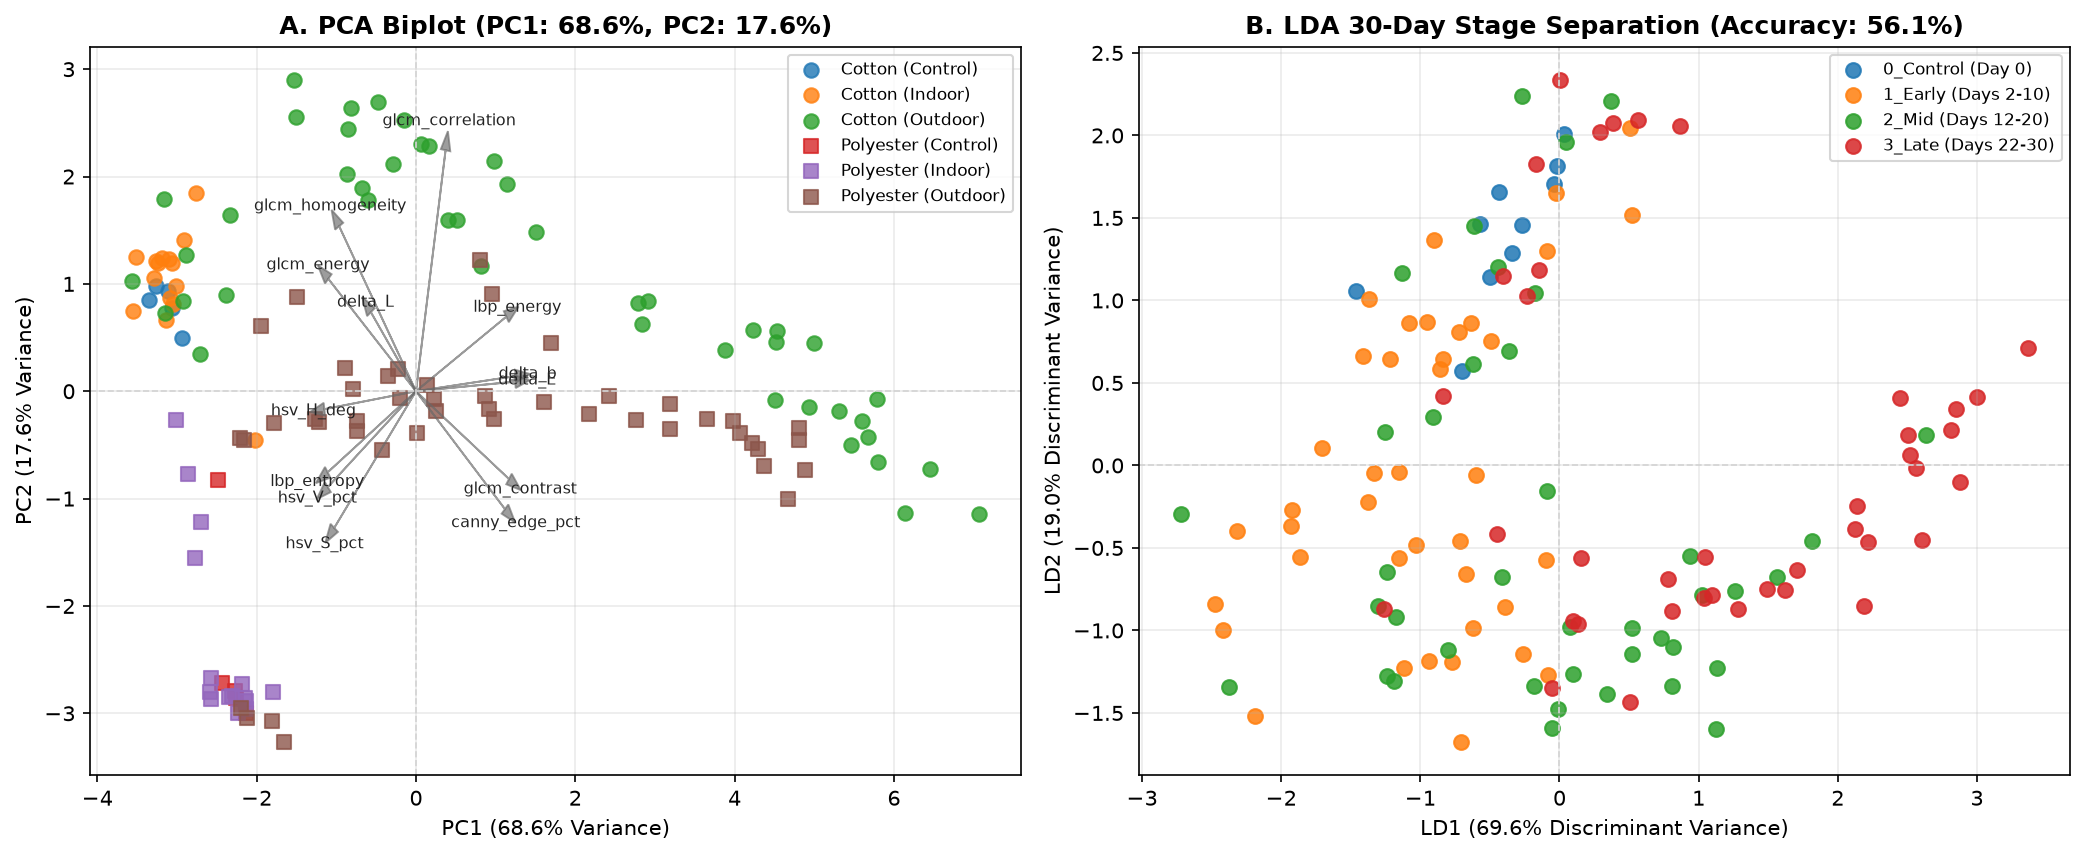

,PC1,PC2,PC3
delta_E,0.3282,0.0235,0.0430
delta_L,-0.1489,0.1938,0.9090
delta_b,0.3291,0.0371,0.0545
hsv_H_deg,-0.3026,-0.0440,-0.0089
hsv_S_pct,-0.2699,-0.3349,-0.0459
hsv_V_pct,-0.2911,-0.2349,0.2939
glcm_contrast,0.3073,-0.2151,0.0408
glcm_homogeneity,-0.2537,0.4045,-0.1395
glcm_energy,-0.2895,0.2755,-0.1596
glcm_correlation,0.0978,0.5908,-0.0656


In [5]:
mv_results = run_pca_and_lda(master_df, feature_cols=CORE_FEATURES)

scores_df = mv_results["scores_df"]
loadings_df = mv_results["loadings_df"]
pca_var = mv_results["pca_var_ratio"]
lda_var = mv_results["lda_var_ratio"]

scores_df.to_csv(TABLES_DIR / "multivariate_scores_pca_lda.csv", index=False)
loadings_df.to_csv(TABLES_DIR / "pca_feature_loadings.csv")

print(f"PCA Explained Variance -> PC1: {pca_var[0]*100:.2f}% | PC2: {pca_var[1]*100:.2f}% (Cumulative: {(pca_var[0]+pca_var[1])*100:.2f}%)")
print(f"LDA 30-Day Stage Separation Accuracy: {mv_results['lda_accuracy']*100:.2f}%")

fig, axes = plt.subplots(1, 2, figsize=(14, 5.8))

# --- Panel A: PCA Biplot (Samples + Feature Vectors) ---
ax_pca = axes[0]
for (fab, setting), grp in scores_df.groupby(["fabric", "setting"]):
    marker = "o" if fab == "Cotton" else "s"
    ax_pca.scatter(grp["PC1"], grp["PC2"], marker=marker, s=48, alpha=0.8, label=f"{fab} ({setting})")

scale_arrow = 3.8
for feat_name in loadings_df.index:
    vx = loadings_df.loc[feat_name, "PC1"] * scale_arrow
    vy = loadings_df.loc[feat_name, "PC2"] * scale_arrow
    ax_pca.arrow(0, 0, vx, vy, color="dimgray", alpha=0.65, head_width=0.12, linewidth=0.9)
    ax_pca.text(vx * 1.12, vy * 1.12, feat_name, fontsize=7.5, color="#222222", ha="center", va="center")

ax_pca.axhline(0, color="lightgray", linestyle="--", linewidth=0.8)
ax_pca.axvline(0, color="lightgray", linestyle="--", linewidth=0.8)
ax_pca.set_title(f"A. PCA Biplot (PC1: {pca_var[0]*100:.1f}%, PC2: {pca_var[1]*100:.1f}%)", fontweight="bold")
ax_pca.set_xlabel(f"PC1 ({pca_var[0]*100:.1f}% Variance)")
ax_pca.set_ylabel(f"PC2 ({pca_var[1]*100:.1f}% Variance)")
ax_pca.legend(fontsize=8, frameon=True)
ax_pca.grid(True, alpha=0.25)

# --- Panel B: LDA Supervised Exposure Stage Separation ---
ax_lda = axes[1]
for stage, grp in sorted(scores_df.groupby("exposure_stage")):
    ax_lda.scatter(grp["LD1"], grp["LD2"], s=50, alpha=0.85, label=stage)

ax_lda.axhline(0, color="lightgray", linestyle="--", linewidth=0.8)
ax_lda.axvline(0, color="lightgray", linestyle="--", linewidth=0.8)
ax_lda.set_title(f"B. LDA 30-Day Stage Separation (Accuracy: {mv_results['lda_accuracy']*100:.1f}%)", fontweight="bold")
ax_lda.set_xlabel(f"LD1 ({lda_var[0]*100:.1f}% Discriminant Variance)")
ax_lda.set_ylabel(f"LD2 ({lda_var[1]*100:.1f}% Discriminant Variance)")
ax_lda.legend(fontsize=8, frameon=True)
ax_lda.grid(True, alpha=0.25)

plt.tight_layout()
mv_fig_path = FIGURES_DIR / "pca_biplot_and_lda_stages.png"
plt.savefig(mv_fig_path, dpi=300)
plt.show()

display(loadings_df[["PC1", "PC2", "PC3"]])

## 5. Unsupervised Hierarchical Cluster Analysis (HCA Dendrogram)
Finally, **Ward's minimum-variance hierarchical clustering** (Euclidean distance on standardized color and texture features) is computed across group-day profiles to visualize natural unlabelled sample groupings—demonstrating how clean controls, indoor fabrics, and progressively degraded outdoor samples cluster organically across the 30-day exposure period.

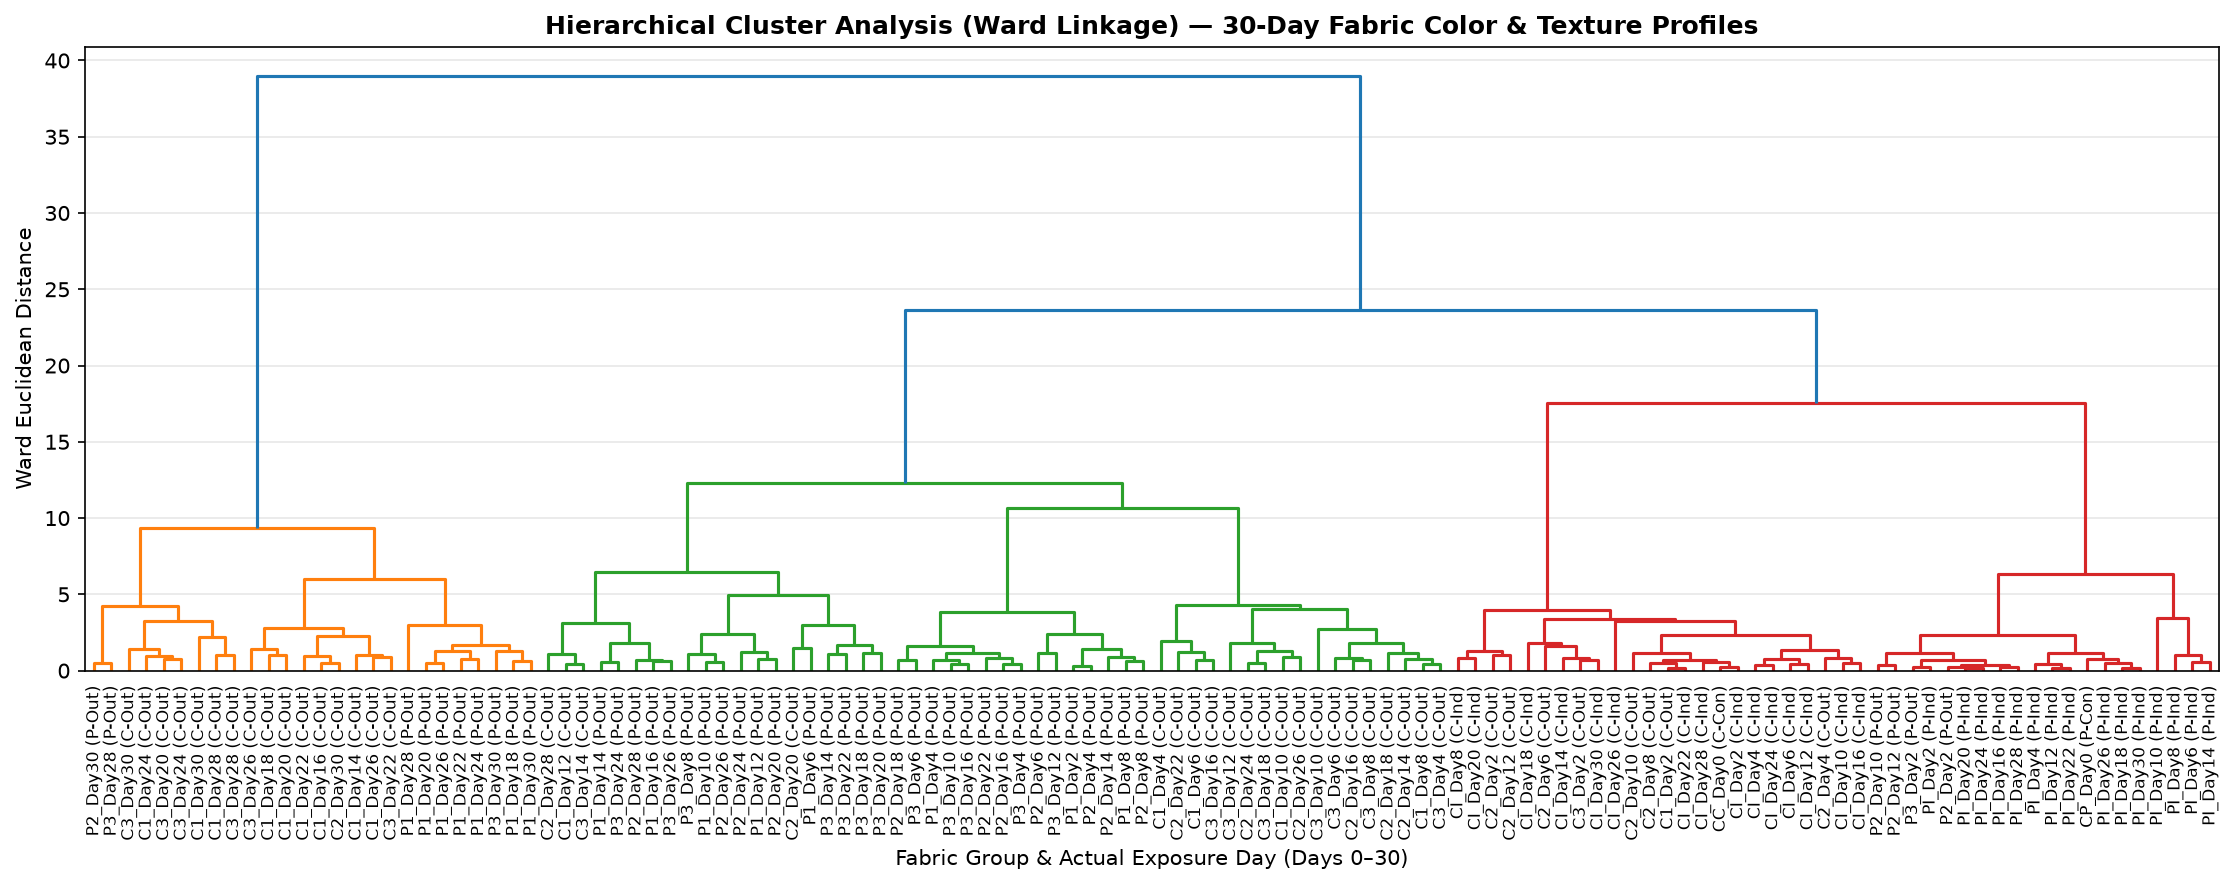

Saved HCA dendrogram to: /Users/anna/PycharmProjects/Fabric_FYP/outputs/figures/hca_ward_dendrogram.png


In [6]:
# Aggregate mean feature profile per (Group Code, Exposure Day)
profile_df = (
    master_df.groupby(["group_code", "fabric", "setting", "day"])[CORE_FEATURES]
    .mean()
    .reset_index()
)

labels = [
    f"{row['group_code']}_Day{row['day']} ({row['fabric'][0]}-{row['setting'][:3]})"
    for _, row in profile_df.iterrows()
]

X_prof_scaled = StandardScaler().fit_transform(profile_df[CORE_FEATURES].to_numpy(dtype=float))
Z = linkage(X_prof_scaled, method="ward")

fig, ax = plt.subplots(figsize=(15, 6))
dendrogram(
    Z,
    labels=labels,
    leaf_rotation=90,
    leaf_font_size=8.0,
    color_threshold=0.55 * max(Z[:, 2]),
    ax=ax,
)
ax.set_title("Hierarchical Cluster Analysis (Ward Linkage) — 30-Day Fabric Color & Texture Profiles", fontweight="bold")
ax.set_xlabel("Fabric Group & Actual Exposure Day (Days 0–30)")
ax.set_ylabel("Ward Euclidean Distance")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
hca_fig_path = FIGURES_DIR / "hca_ward_dendrogram.png"
plt.savefig(hca_fig_path, dpi=300)
plt.show()
print("Saved HCA dendrogram to:", hca_fig_path)